<a href="https://colab.research.google.com/github/MaulanaFatullah/232310006-lab-pengolahan-citra-semester-7/blob/main/pertemuan_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from google.colab.patches import cv2_imshow
from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


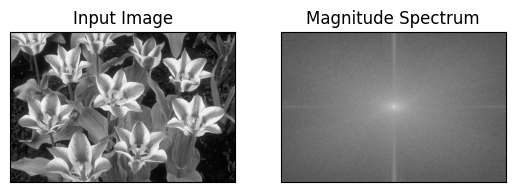

In [5]:
#MAGNITUDE SPECTRUM
# img_raw = cv2.imread('/content/drive/MyDrive/!IBIK/Semester 7/Lab. Pengolahan Citra/Footage/tulips.tif', 1)

img = cv2.imread('/content/drive/MyDrive/!IBIK/Semester 7/Lab. Pengolahan Citra/Footage/tulips.tif', 0)

f = np.fft.fft2(img) #2D Discrete Fourier Transform (DFT)
fshift = np.fft.fftshift(f)
magnitude_spectrum =  20*np.log(np.abs(fshift)) #Menghitung Magnitude Spectrum

#Visualisasi
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])

plt.show()



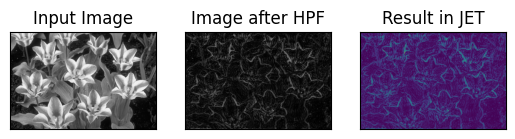

In [6]:
fshift = np.fft.fftshift(np.fft.fft2(img))

rows, cols = img.shape

#center row center cols
crow,ccol = rows//2 , cols//2
#isi invers
fshift[crow - 30: crow + 31, ccol - 30:ccol + 31] = 0
#nilai dikembalikan pada img_back
f_ishift = np.fft.ifftshift(fshift)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

plt.subplot(131),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(132),plt.imshow(img_back, cmap = 'gray')
plt.title('Image after HPF'), plt.xticks([]), plt.yticks([])

plt.subplot(133),plt.imshow(img_back)
plt.title('Result in JET'), plt.xticks([]), plt.yticks([])

plt.show()

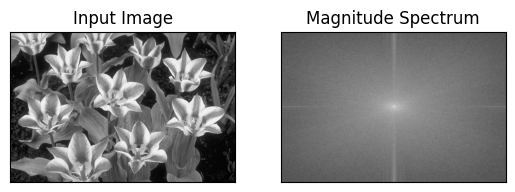

In [10]:
#dft nama atribut, kemudian dibuat ke data aslii dan imajiner
dft = cv2.dft(np.float32(img), flags = cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

#hasil visualisasi ditampilkan
magnitude_spectrum = 20*np.log(cv2.magnitude(dft_shift[:,:,0], dft_shift[:,:,1]))

#tampilin dan format 1 baris 2 kolom
plt.subplot(121), plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()



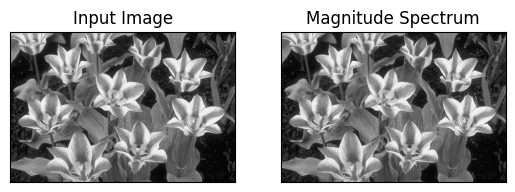

In [25]:
#penerapan filter magnitude spectrum
rows, cols = img.shape

#ambil nilai tengah
crow, ccol = rows//2, cols//2

#buat array kosong dengan skala 1L1 format 0-255
mask = np.ones((rows, cols, 2), np.uint8)
mask[crow-30:crow+30, ccol-30:ccol+30] = 1

#kalikan nilai dengan nilai maskingnya
fshift = dft_shift*mask

# Kembalikan ke nilai semula dan ditampung pada variabel fshift
f_ishift = np.fft.ifftshift(fshift)
img_back = cv2.idft(f_ishift)

#ambil data asli dan imajiner, tidak menggunakan absolut
img_back = cv2.magnitude(img_back[:, :, 0], img_back[:, :, 1])

plt.subplot(121), plt.imshow(img, cmap = 'gray')
plt.title('Input Image,'), plt.xticks([]), plt.yticks([])sa

plt.subplot(122), plt.imshow(img_back, cmap = 'gray')
plt.title('Magnitude Spectrum,'), plt.xticks([]), plt.yticks([])
plt.show()

In [19]:
#OPtiMASI DFT

img2 = cv2.imread('/content/drive/MyDrive/!IBIK/Semester 7/Lab. Pengolahan Citra/Footage/tulips.tif', 0)
rows, cols = img2.shape

nrows = cv2.getOptimalDFTSize(rows)
ncols = cv2.getOptimalDFTSize(cols)
print(nrows, cols)

512 768


In [22]:
#Perbandingan DFT pada numpy

nimg = np.zeros((nrows, ncols))
nimg[:rows, :cols] = img2

%timeit fft1 = np.fft.fft2(img2)
%timeit fft2 = np.fft.fft2(img2, [nrows, ncols])

12.4 ms ± 2.05 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)
10.2 ms ± 200 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [24]:
%timeit dft1 = cv2.dft(np.float32(img2), flags=cv2.DFT_COMPLEX_OUTPUT)
%timeit dft2 = cv2.dft(np.float32(nimg), flags=cv2.DFT_COMPLEX_OUTPUT)


3.36 ms ± 243 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)
3.53 ms ± 482 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


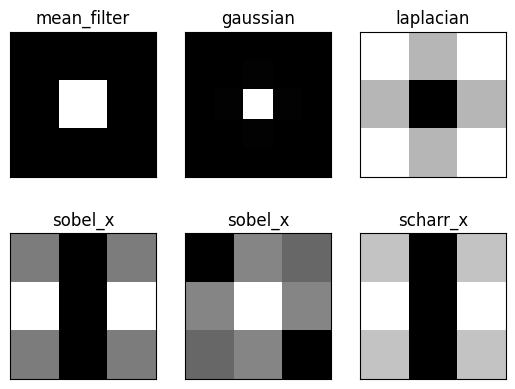

In [33]:
mean_filter = np.ones((3,3))

x = cv2.getGaussianKernel(5, 10)
gaussian = x*x.T

scharr = np.array([[-3, 0,3], [-10,0,10], [-3, 0, 3]])
sobel_x = np.array([[-1, 0,1], [-2,0,2], [-1, 0, 1]])
sobel_y = np.array([[-1, 2,1], [0,0,0], [1, 2, 1]])

laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])

filters = [mean_filter, gaussian, laplacian, sobel_x, sobel_y, scharr]
filter_name = ['mean_filter', 'gaussian', 'laplacian', 'sobel_x', 'sobel_x', 'scharr_x']

fft_filters = [np.fft.fft2(x) for x in filters]
fft_shift = [np.fft.fftshift(y) for y in fft_filters]
mag_spectrum = [np.log(np.abs(z)+1) for z in fft_shift]
for i in range(6):
  plt.subplot(2,3,i+1),plt.imshow(mag_spectrum[i], cmap = 'gray')
  plt.title(filter_name[i]), plt.xticks([]), plt.yticks([])
plt.show()


Domain Filter - Cartoonify


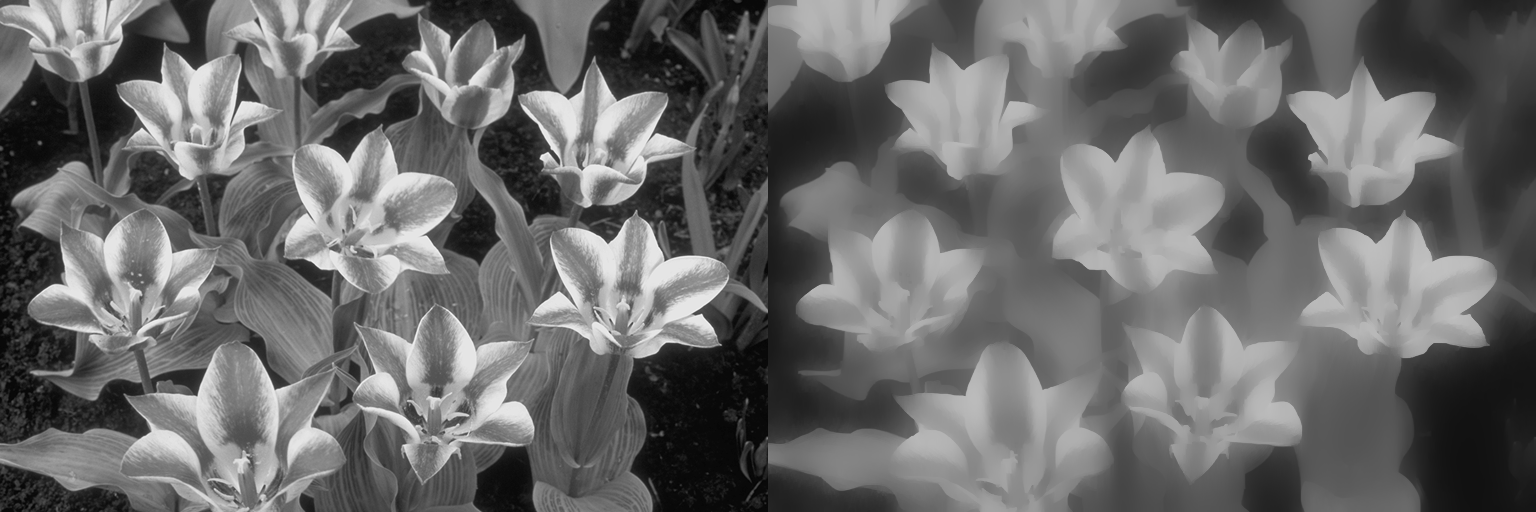

In [35]:
src = cv2.imread('/content/drive/MyDrive/!IBIK/Semester 7/Lab. Pengolahan Citra/Footage/tulips.tif', 0)

# Cartoonify menggunakan filter yang mempertahankan tepi
DF = cv2.edgePreservingFilter(src, flags=1, sigma_s=60, sigma_r=0.4)

# Menampilkan citra asli dan citra yang telah di-cartoonify
print('Domain Filter - Cartoonify')
cv2_imshow(np.hstack((src, DF)))

Gaussian Smoothing


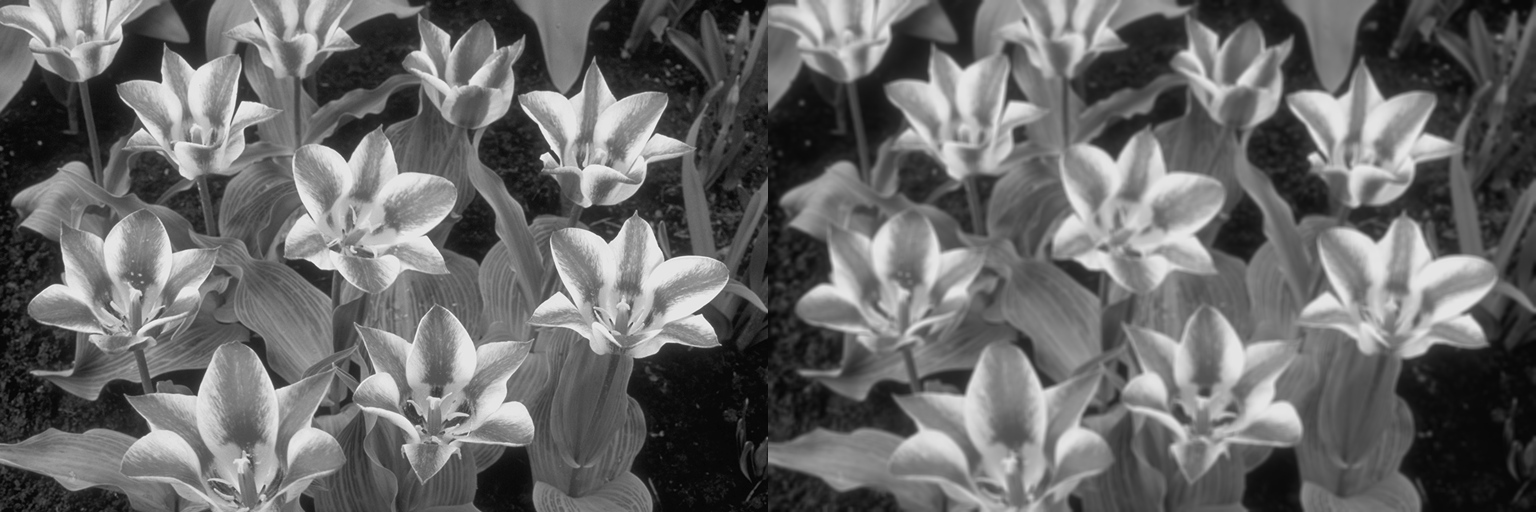

In [36]:
dst = cv2.GaussianBlur(src,(5,5), cv2.BORDER_DEFAULT)
print('Gaussian Smoothing')
cv2_imshow(np.hstack((src, dst)))